# Step 4: Scaling pipeline and time-aware evaluation protocols

**Goal:** build the shared "test bench" that every later model will use, and prove it cannot leak test data.

It has three parts:
1. **Scaling pipeline:** the scaler sits inside the model pipeline, so it is fitted on the training batches only.
2. **Three protocols:** A (train 1-3, test 4-10), B (train 1, test each later batch), C (rolling).
3. **Metrics:** accuracy, macro precision, macro recall, macro F1 and confusion matrices.

The code is in `src/evaluation.py`; the leakage tests are in `tests/test_evaluation.py`.
At the end we run two *sanity checks* only to show the bench works. They are **not** the Step 5 baselines.

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # silences a harmless Windows core-count warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from src import data_loader as dl
from src import evaluation as ev

pd.set_option("display.width", 150)
df = dl.remove_toluene(dl.load_all())
print("Rows:", len(df))

Rows: 12077


## 1. The three protocols

In [2]:
rows = []
for p in "ABC":
    for s in ev.get_splits(p):
        ev.check_split(s)
        rows.append({"protocol": s.protocol, "split": s.name,
                     "train_batches": str(list(s.train_batches)), "test_batches": str(list(s.test_batches))})
protocols = pd.DataFrame(rows)
protocols.to_csv("../results/step4_protocols.csv", index=False)
protocols

,protocol,split,train_batches,test_batches
0,A,train 1-3 / test 4-10,"[1, 2, 3]","[4, 5, 6, 7, 8, 9, 10]"
1,B,train 1 / test 2,[1],[2]
2,B,train 1 / test 3,[1],[3]
3,B,train 1 / test 4,[1],[4]
4,B,train 1 / test 5,[1],[5]
5,B,train 1 / test 6,[1],[6]
6,B,train 1 / test 7,[1],[7]
7,B,train 1 / test 8,[1],[8]
8,B,train 1 / test 9,[1],[9]
9,B,train 1 / test 10,[1],[10]


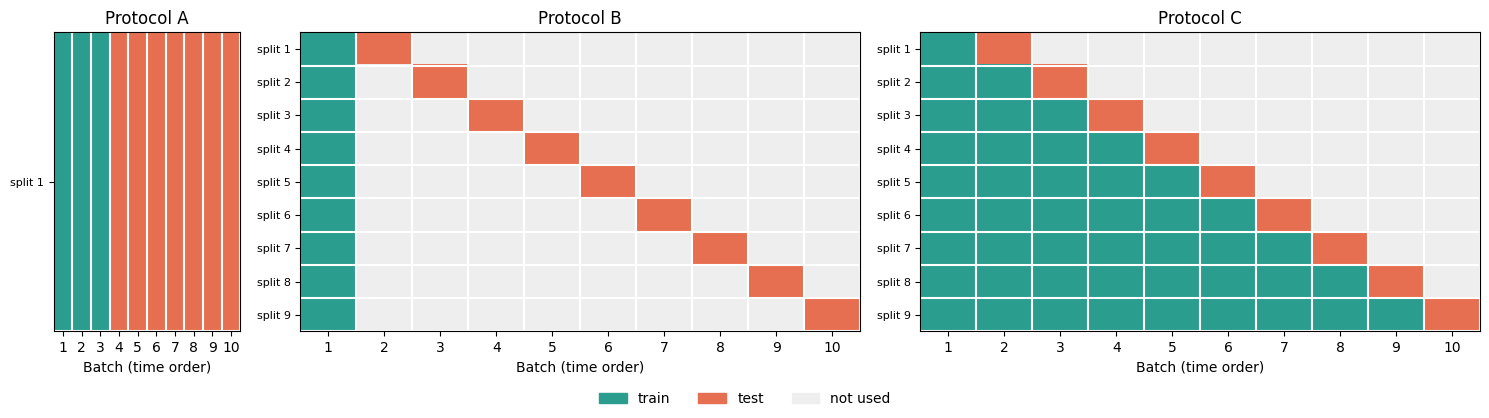

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 3, 3]})
cmap = ListedColormap(["#eeeeee", "#2a9d8f", "#e76f51"])   # unused, train, test
titles = {"A": "Protocol A", "B": "Protocol B", "C": "Protocol C"}
for ax, p in zip(axes, "ABC"):
    splits = ev.get_splits(p)
    grid = np.zeros((len(splits), 10))
    for i, s in enumerate(splits):
        for b in s.train_batches: grid[i, b - 1] = 1
        for b in s.test_batches: grid[i, b - 1] = 2
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    ax.set_xticks(range(10)); ax.set_xticklabels(range(1, 11))
    ax.set_yticks(range(len(splits)))
    ax.set_yticklabels([f"split {i + 1}" for i in range(len(splits))], fontsize=8)
    ax.set_xlabel("Batch (time order)")
    ax.set_title(titles[p])
    ax.set_xticks(np.arange(-.5, 10, 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(splits), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2a9d8f", "#e76f51", "#eeeeee"]]
fig.legend(handles, ["train", "test", "not used"], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("../results/step4_protocols.png", dpi=150)
plt.show()

**How to read it:** each row is one train/test split. Green batches are used to train the model and orange batches
to test it. In every row the test batches come *after* the training batches in time, and no batch is both. This is
checked by code (`check_split`) and by tests.

## 2. Does the bench leak? (checked by tests)

In [4]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "tests/test_evaluation.py", "-q", "-p", "no:cacheprovider"],
                     capture_output=True, text=True, cwd=Path.cwd().parent)
print(out.stdout.strip().splitlines()[-1])
assert out.returncode == 0, "evaluation tests failed\n" + out.stdout

15 passed in 4.80s


The tests prove, among other things, that:
- the model is fitted on exactly the training rows and predicts exactly the test rows;
- the scaler's mean equals the **training** mean, not the all-data mean;
- if we multiply all test-batch features by 1000, the fitted scaler does not change at all;
- every protocol has no train/test overlap and always tests on later batches;
- the metric functions give the right answers on a small hand-checked example.

## 3. Sanity checks (not the Step 5 baselines)

**Check 1: majority-class model.** It always predicts the most common gas of the training batches. A real model must beat this.

In [5]:
rows = []
for p in "ABC":
    metrics, preds = ev.run_protocol(lambda: ev.make_pipeline(DummyClassifier(strategy="most_frequent")), df, p)
    rows.append({"protocol": p, **ev.summarize(metrics)})
majority = pd.DataFrame(rows).set_index("protocol")
majority.round(3)

,mean_accuracy,mean_macro_f1,weighted_accuracy,min_accuracy
protocol,,,,
A,0.208,0.068,0.226,0.109
B,0.226,0.073,0.242,0.109
C,0.218,0.071,0.225,0.109


**What to notice:** always guessing the most common training gas gives only about 21-23% accuracy and about 7%
macro-F1, which is what we expect for 5 gases. Any real model must clearly beat this. The macro-F1 is far lower than
accuracy because the model never predicts four of the five gases.

**Check 2: does scaling matter?** The same plain kNN (k = 5, no tuning) on protocol A, with and without the scaler.
This is only to show why the scaler is in the pipeline.

In [6]:
with_scaler, _ = ev.run_protocol(lambda: ev.make_pipeline(KNeighborsClassifier(5)), df, "A")
without_scaler, _ = ev.run_protocol(lambda: KNeighborsClassifier(5), df, "A")

cmp = pd.DataFrame({
    "with scaler": with_scaler.set_index("test_batch")["accuracy"],
    "without scaler": without_scaler.set_index("test_batch")["accuracy"],
})
cmp.round(3)

,with scaler,without scaler
test_batch,,
4,0.733,0.745
5,0.756,0.924
6,0.789,0.638
7,0.737,0.572
8,0.518,0.217
9,0.783,0.653
10,0.598,0.472
pooled,0.696,0.555


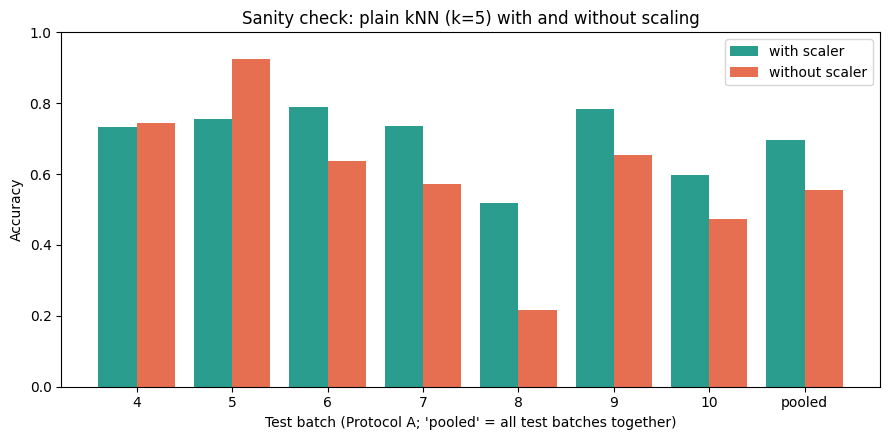

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(cmp))
ax.bar(x - 0.2, cmp["with scaler"], 0.4, label="with scaler", color="#2a9d8f")
ax.bar(x + 0.2, cmp["without scaler"], 0.4, label="without scaler", color="#e76f51")
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in cmp.index])
ax.set_ylim(0, 1); ax.set_ylabel("Accuracy"); ax.set_xlabel("Test batch (Protocol A; 'pooled' = all test batches together)")
ax.set_title("Sanity check: plain kNN (k=5) with and without scaling")
ax.legend()
plt.tight_layout()
plt.savefig("../results/step4_scaling_sanity.png", dpi=150)
plt.show()
cmp.round(4).to_csv("../results/step4_scaling_sanity.csv")
majority.round(4).to_csv("../results/step4_majority_baseline.csv")

**What to notice (plain kNN, k = 5, untuned; this is not the Step 5 baseline):**
- Over all test batches together ("pooled"), scaling raises accuracy from 55.5% to 69.6%.
- It helps clearly on batches 6-10 (for example batch 8: 21.7% to 51.8%), but **not in every batch**: batches 4 and 5
  are better without scaling (batch 5: 92.4% unscaled vs 75.6% scaled). Those two batches are also the smallest
  (161 and 197 samples), and we did not investigate why.
- Without scaling, kNN distances are dominated by the features with the largest numbers (see Step 2), so it
  effectively ignores most of the 128 features.

So the scaler is the right default, but a result like this on a single small batch should not be over-read.
All real numbers will come from Step 5 onwards.

## Summary of Step 4
- Protocols A, B and C are defined in code, with automatic checks that train and test never overlap and that test
  batches are always later in time.
- The scaler is inside the pipeline, so it is fitted on training batches only. Tests prove that changing the test
  data cannot change the fitted scaler.
- Metrics: accuracy, macro precision, macro recall, macro F1 and confusion matrices.
- Sanity checks: the majority-class model gets about 21-23% accuracy, and plain scaled kNN gets 69.6% pooled
  on protocol A, so the bench works and gives sensible numbers.